# The 2μ2e background estimate per bin of the LJ-pair mass

This notebook evaluates the 2μ2e background estimate of `estimate.ipynb` per bin of the LJ-pair
mass M instead of once over M ≥ 150 GeV, compares the sum over the bins with the one-bin estimate,
and measures with a toy expected limit what a binned search region would gain. The vocabulary is
that of `estimate.ipynb`: object 0 is the leading muon LJ, object 1 the egamma LJ (2μ2e) or the
subleading muon LJ (4μ); the planes **PP, PD, DP, DD** say whether the muon LJ (first letter) and
the other LJ (second letter) are prompt or displaced; inside each plane **A** (iso0 < 0.25 and
$|\Delta\phi| \ge 2.4$, with iso1 < 0.5) is the search region, **B** fails the isolation, **C**
fails $|\Delta\phi|$ and **D** fails both; **κ** = A D / (B C) of a plane is one when its two axes
are independent; `dsa0` and `dsa1+` split the muon LJs by their number of displaced-standalone
(DSA) muons. The histograms (the `abcd8d` campaign, "8D inputs" below) store the LJ-pair mass in
the bins 150–200, 200–300, 300–400, 400–600, 600–800, 800–1000 and ≥ 1000 GeV above the 150 GeV
edge; "cube bins" names the binning made of them. Signal yields are "at the stored cross section":
the cross section the samples were normalised to when the histograms were filled
(`cross_sections.yaml` of the repository), the signal strength μ = 1 of the toy limits.

**The one-bin estimate.** A of the search plane DD over M ≥ 150 GeV is estimated by the B route:
B of DD times A/B of PD, per DSA class of the muon LJ, summed over the two classes. It gives
**61.3 ± 8.0 (stat.) events with a 33% systematic uncertainty**, set by the two open tests of the
route's assumption (PP → DP, observed over predicted 1.32 ± 0.27; DD below 150 GeV,
1.00 ± 0.25).

**Why bin in mass.** The one-bin estimate averages a transfer factor that falls by about 40%
between 150 and 600 GeV over a window where about 70% of the background lies (41 of the 61 events
at 150–300 GeV) but none of the heavy signal does (the 500–1000 GeV points have more than 99.8% of
their yield above 300 GeV). Binning in mass borrows each bin's own factor, at the masses of the
search plane's B events, and moves most of the background out of the heavy points' bins. The price
is statistics — fewer B events of DD and fewer PD events per bin — and a weaker validation per bin:
the 33% comes from tests over the whole window, and above 300 GeV only the PP → DP test exists
(1.5 ± 0.5).

**The factor in a bin.** Per bin and DSA class, A/B of PD is measured in the bin. Where PD
measures it to 20% or better (the larger side of its 68% interval over its value) the measurement
is used; elsewhere the factor comes from a fit of A/B against M over the seven mass bins of the
histograms above 150 GeV, evaluated at the mean mass of the search plane's B events in the bin,
and |measured − fitted| enters as a shape systematic. The fit is a binomial likelihood: in every
bin the A count is binomial among the A + B events with pass probability r/(1 + r), r the form's
A/B at the bin's mass, so that a bin without an A event (an upper limit on A/B) or without a B
event (a lower limit) enters like any other. Two forms: the exponential A/B = a exp(−M/M₀), which
stays positive at every mass, and the straight line A/B = a + b M. The design note written before
this study listed the line first and the exponential as the alternative; this notebook was written
with the exponential as the nominal form, for its positivity, before any fit was run, and reports
the two side by side throughout. The two forms give the same estimates to 1%, but they do not lead
to the same choice of binning: the ≥ 600 GeV bin's estimate falls on either side of the rule's
3-event threshold (section 5, section 7). An earlier version of the notebook fitted the measured
ratios by least squares, which left the bins without an A or a B event out; the likelihood fit
replaced it after the first run, and section 3 says what that changed.

**The decision rule**, written down in the design note before any result, quoted as written
there:

> choose the binning that maximises the expected limit for the 500 and 800 GeV points, subject to: every search bin's B route has >= 5 B events in DD (stat <= 45%) or a background below 3 events (Poisson floor), per-bin A/B used where PD's A/B error <= 20% else the fitted value with |per-bin - fit| as a shape systematic; 150-300 stays a SEARCH bin (m_B=200 is a signal hypothesis until the group drops it); never look at A of DD; no selection on kappa or on closure outcome.

How it is applied (`binning_lib.rule_table`):

- *Maximises the expected limit* means the strongest expected limit: the lowest expected upper
  limit on the signal, taken relative to the one-bin estimate.
- The candidates are the four binnings of `binning_lib.BINNINGS`, fixed in advance: one bin
  (M ≥ 150 GeV); two windows (150–300, ≥ 300 GeV); three bins (150–300, 300–600, ≥ 600 GeV); and
  the histograms' own bins up to 600 GeV (150–200, 200–300, 300–400, 400–600, ≥ 600 GeV).
- The decision points are the 500 GeV point and the three 800 GeV points of the signal list. Each
  mass counts once: the relative limits are averaged over the points of each mass, then over the
  two masses.
- The limits are those of the selected factor (the rule's second clause), with the 33% systematic
  of `estimate.ipynb` as one nuisance common to all bins; section 5 shows two other readings of
  the systematic beside it, independent per bin and sized per bin by the open test.
- *A background below 3 events* is read on the selected estimate's central value, as the rule
  says; the parentheses of the rule explain its two thresholds (five B events give a 45% Poisson
  error; three events is where a limit stops depending on the background) and add no condition.
- *150–300 GeV stays a search bin* is read as: the range stays in the search region, as one bin or
  split, and is never made a control region. Every candidate satisfies it.
- *A of DD is never looked at*: the data cubes hide it in every mass bin above 150 GeV, no function
  of this notebook reads it, and the tables print "blind" where it would stand.
- *Nothing is selected on kappa or on closure*: the binnings are fixed in advance, the choice of
  factor depends only on PD's statistical precision, and the choice among binnings only on the toy
  limits and the count requirement. κ of the open planes is printed as context only.

**Blinding.** As in `estimate.ipynb`: data cubes are loaded only through
`transfer_lib.summed_cubes`, which hides A of DD above 150 GeV in both channels and, in 4μ, A of DP
and PD as well. Every mass sub-range of a hidden region projects to NaN and prints as "blind".
Signal cubes are never hidden.

**Uncertainties.** As in `estimate.ipynb`: 68.27% Clopper–Pearson intervals for ratios of disjoint
counts, relative errors added in quadrature for products and ratios of ratios, absolute errors
added in quadrature for sums over classes and bins, the 68% upper limit of 1.84 events times the
factor for a count of zero; a "±" is printed where the two sides of an interval agree within 5%,
otherwise "−m +p".

In [1]:
import dataclasses
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import abcd6d_io as io
import transfer_lib as tl
import transfer_plots as tp
import plane_search_lib as ps
import plane_search_plots as pp
import estimate_lib as el
import binning_lib as bl
import binning_plots as bp

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 200)
tp.set_style()

BASE = os.environ.get("ABCD8D_LOCAL", "/uscms_data/d3/murtazas/abcd8d_local")
print("8D inputs:", BASE)
data = tl.summed_cubes(BASE, "data", prefix="abcd8d")
print("hidden box:", io.blind_signature(prefix="abcd8d"))
for t, c in data.items():
    print(f"{t}: {c.sumw.shape}, {int(np.isnan(c.sumw).sum())} hidden cells, {np.nansum(c.sumw):.0f} open events")
d2, d4 = data["2mu2e"], data["4mu"]
NOMINAL = ps.Config(fail0=0.25, dphi_fail=2.4)             # no buffer between A and its sidebands
WINDOWS = [("M >= 150", NOMINAL),
           ("150-300", dataclasses.replace(NOMINAL, mass=(150.0, 300.0))),
           ("M >= 300", dataclasses.replace(NOMINAL, mass=(300.0, None)))]
SIGNAL_POINTS = bl.SIGNAL_POINTS                            # the points of estimate.ipynb
DECISION_POINTS = bl.DECISION_POINTS                        # the 500 and 800 GeV points carry the choice
FORM = "exponential"                                        # the nominal form of the A/B(M) fit; linear is the cross-check
SYST = 0.33                                                 # the systematic uncertainty of the estimate (estimate.ipynb)
print("nominal configuration:", NOMINAL.label())
for name, bins in bl.BINNINGS.items():
    print(f"{name}: {', '.join(label for label, _ in bins)}")
print("decision points:", ", ".join(DECISION_POINTS["2mu2e"]))

8D inputs: /uscms_data/d3/murtazas/abcd8d_local


hidden box: iso0<0.25 iso1<0.5 mass>=150 dphi>=2.4 planes=[('2mu2e', ('displaced', 'displaced')), ('4mu', ('displaced', 'displaced')), ('4mu', ('displaced', 'prompt')), ('4mu', ('prompt', 'displaced'))]
2mu2e: (12, 12, 6, 4, 10, 10, 8, 3), 241920 hidden cells, 23495 open events
4mu: (12, 12, 6, 6, 10, 10, 5, 3, 3), 1360800 hidden cells, 9234 open events
nominal configuration: dphi 2.4/2.4 x iso0 0.25/0.25, iso1<0.5, M>=150
one bin: >=150
two windows: 150-300, >=300
cube bins: 150-200, 200-300, 300-400, 400-600, >=600
three bins: 150-300, 300-600, >=600
decision points: 2Mu2E_500GeV_0p25GeV_0p4mm, 2Mu2E_800GeV_0p25GeV_0p25mm, 2Mu2E_800GeV_1p2GeV_1p2mm, 2Mu2E_800GeV_0p25GeV_1p2mm


## 1. The planes and the per-bin route

The first figure draws the four 2μ2e planes as a 2 × 2 grid of squares, with the data counts over
M ≥ 150 GeV in each cell.

*How to read it.* The squares are arranged by displacement: the muon LJ is prompt in the top row
and displaced in the bottom row, the egamma LJ prompt in the left column and displaced in the right
one. Inside each square the ABCD grid has the muon LJ's isolation running from left (pass,
iso0 < 0.25) to right (fail) and $|\Delta\phi|$ from bottom (fail, below 2.4) to top (pass): A is
the top-left cell, B top right, C bottom left, D bottom right. The hatched cell is A of DD, the
search region, hidden. The solid arrow is the estimate: A/B of PD (the top row of PD's square),
taken per DSA class, applied to B of DD. The dashed arrow is the same step — the muon LJ going from
prompt to displaced — with the egamma LJ prompt, from PP to DP, where A is open: the open test of
the transfer.

The second figure is the estimate of one mass bin as a diagram.

*How to read it.* The axis at the bottom carries the bins of one binning, here three bins; the
highlighted bin is the one whose estimate the boxes spell out: B of DD in the bin for each DSA
class, times A/B of PD of the same class, summed over the two classes. The note above the boxes
says where the factor comes from. The diagram is schematic and carries no numbers; section 4 has
them.

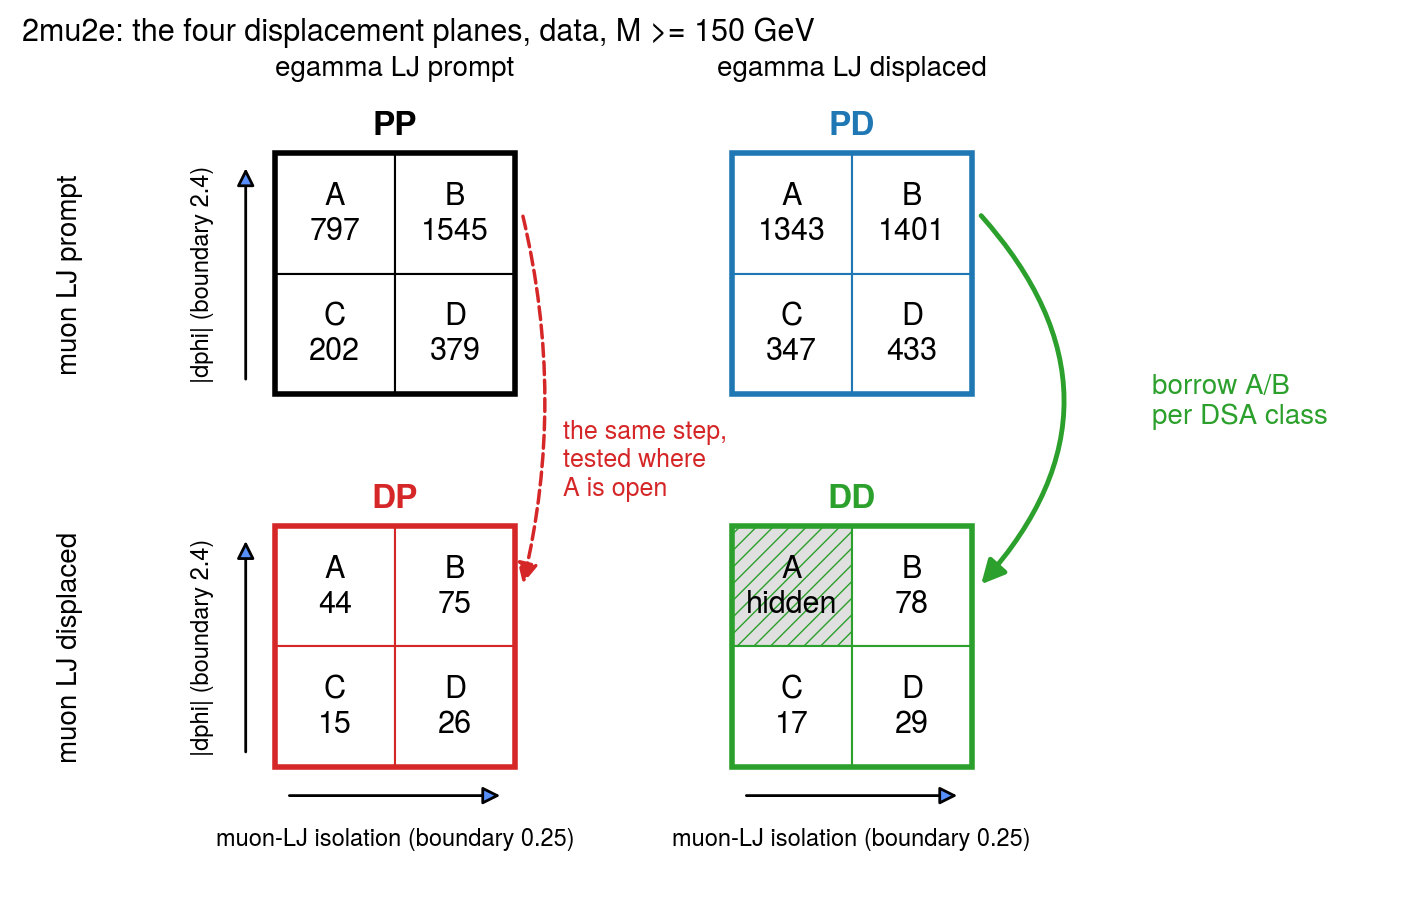

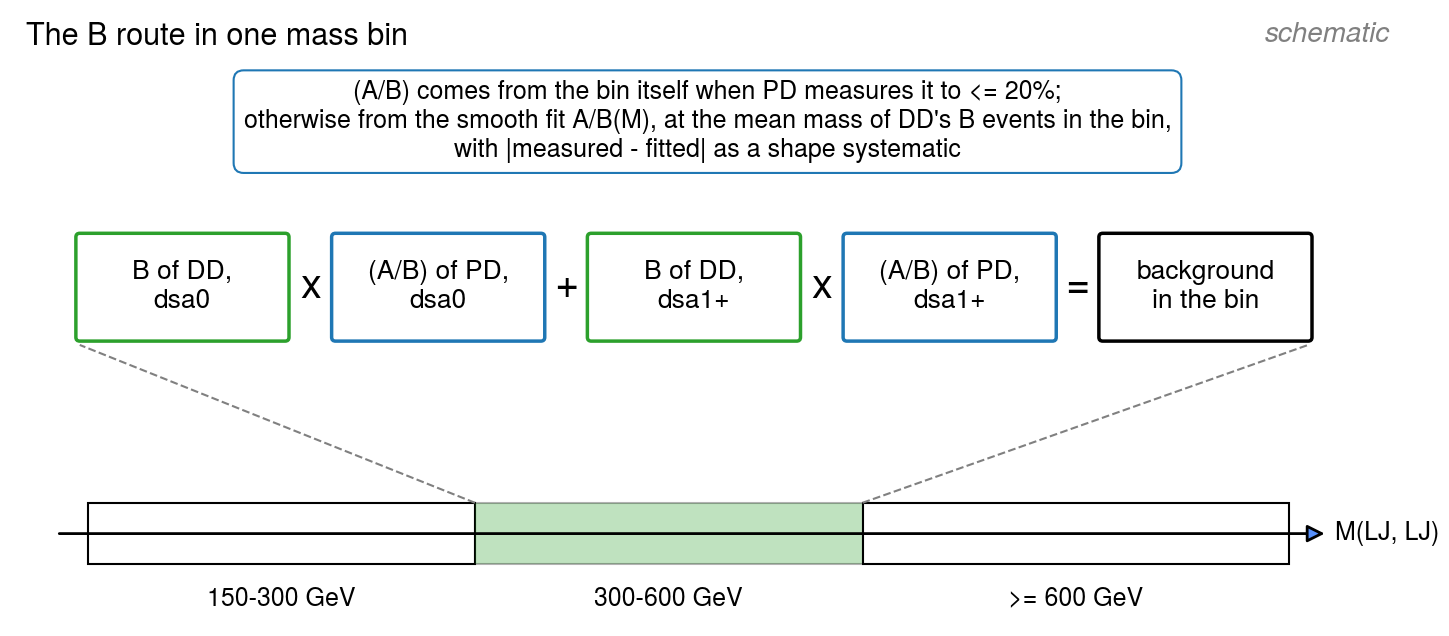

In [2]:
fig = bp.planes_cartoon(d2, NOMINAL, "2mu2e")
plt.show()
fig = bp.route_cartoon()
plt.show()

## 2. Signal, sidebands and the factor against the mass

The first figure shows where each part of the problem sits in mass. Top: the mass distribution of
each signal point in the search region (A of DD, from the signal samples, which are not hidden),
normalised to unit area above 150 GeV, with the inner edges of the candidate binnings as dotted
lines. Bottom: B, C and D of DD in data per mass bin of the histograms. A binning separates the
heavy points from the background only as far as the B events of DD allow, since each bin's estimate
is B of DD in the bin times a factor.

The tables give A, B, C and D, A/B, C/D and κ per mass bin above 150 GeV for DD, PD and PP,
inclusive and per DSA class; A of DD prints "blind" in every bin, and so do its A/B and κ. The last
figure is the one of `estimate.ipynb` section 2.1 — κ, A/B, B/D and C/D of PP and PD against the
mass — here for the trend of A/B.

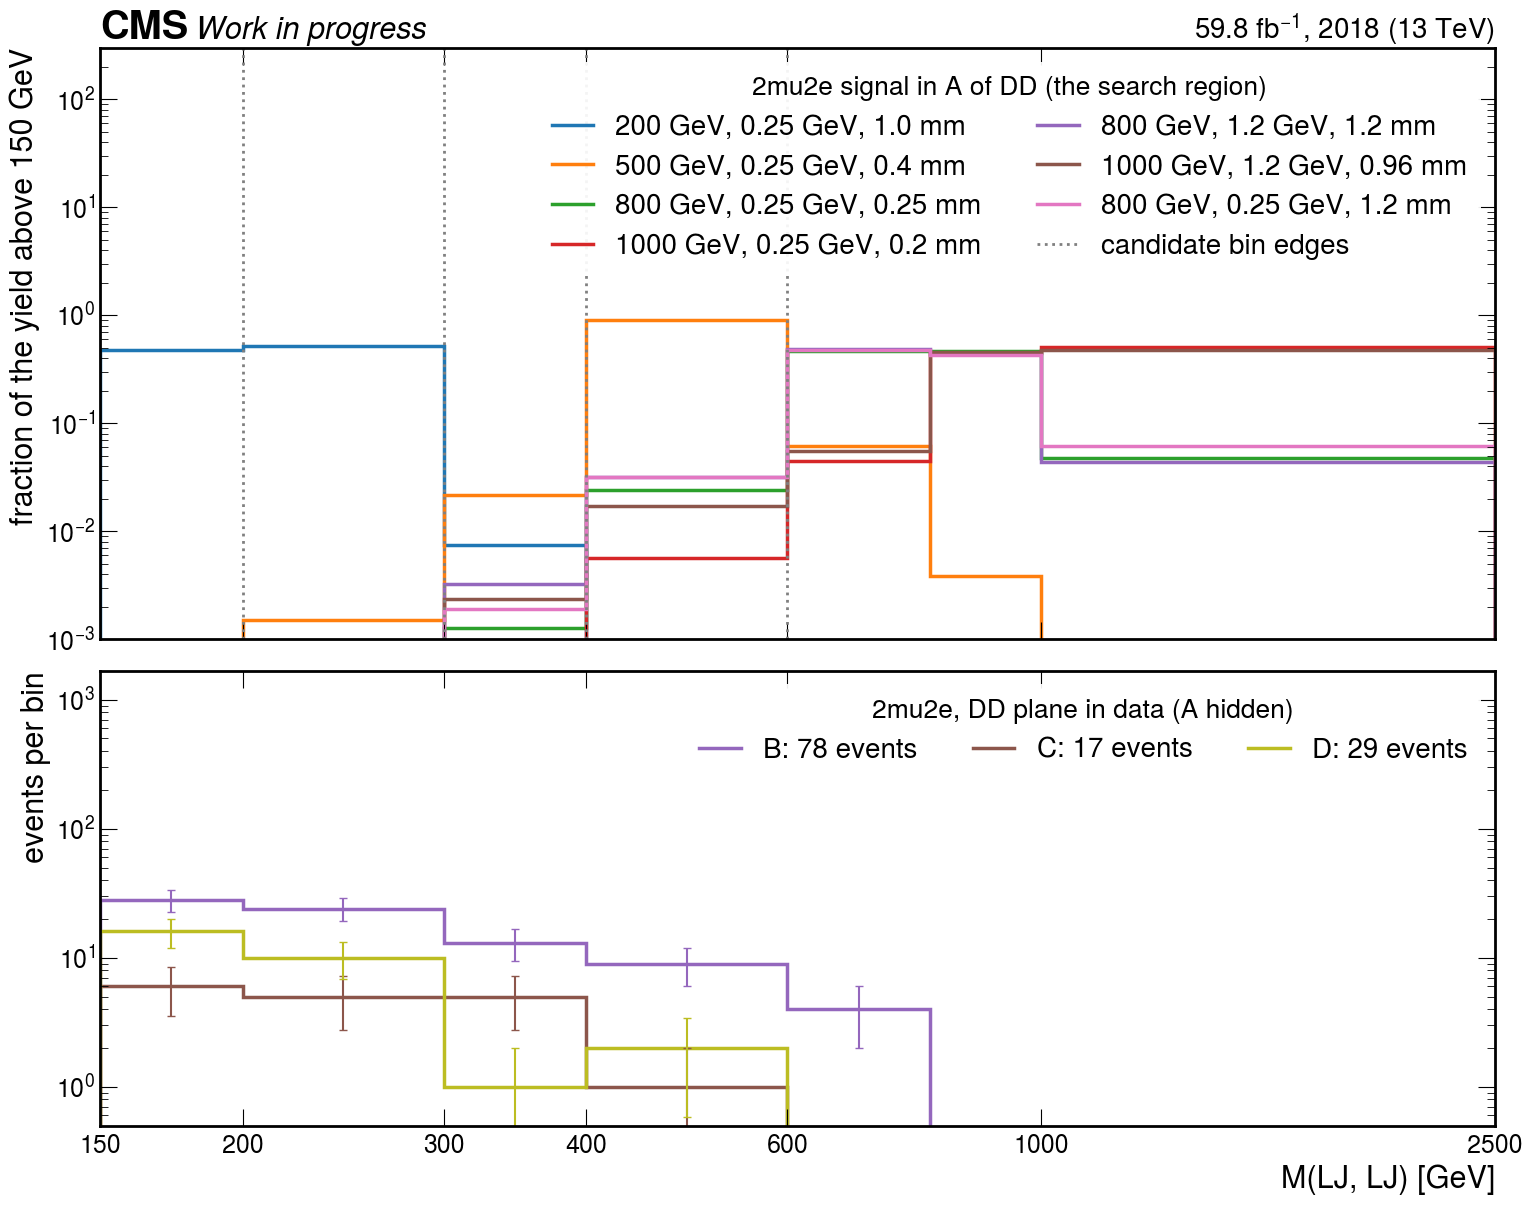

2mu2e, DD: the regions per mass bin and DSA class of the muon LJ


,bin,plane,class,A,B,C,D,A/B,C/D,kappa
0,150-200,DD,all,blind,28,6,16,blind,0.38 -0.17 +0.29,blind
1,150-200,DD,dsa0,blind,15,3,7,blind,0.43 -0.26 +0.61,blind
2,150-200,DD,dsa1+,blind,13,3,9,blind,0.33 -0.20 +0.44,blind
3,200-300,DD,all,blind,24,5,10,blind,0.50 -0.25 +0.48,blind
4,200-300,DD,dsa0,blind,10,5,8,blind,0.62 -0.33 +0.65,blind
5,200-300,DD,dsa1+,blind,14,0,2,blind,0.00 -0.00 +1.51,blind
6,300-400,DD,all,blind,13,5,1,blind,5.00 -3.80 +29.24,blind
7,300-400,DD,dsa0,blind,10,3,0,blind,n/a,blind
8,300-400,DD,dsa1+,blind,3,2,1,blind,2.00 -1.66 +14.87,blind
9,400-600,DD,all,blind,9,1,2,blind,0.50 -0.44 +2.47,blind


2mu2e, PD: the regions per mass bin and DSA class of the muon LJ


,bin,plane,class,A,B,C,D,A/B,C/D,kappa
0,150-200,PD,all,574,530,171,199,1.08 -0.07 +0.07,0.86 -0.09 +0.10,1.26 ± 0.16
1,150-200,PD,dsa0,539,457,146,167,1.18 -0.07 +0.08,0.87 -0.10 +0.11,1.35 ± 0.18
2,150-200,PD,dsa1+,35,73,25,32,0.48 -0.10 +0.12,0.78 -0.20 +0.27,0.61 -0.23 +0.25
3,200-300,PD,all,494,519,105,155,0.95 -0.06 +0.06,0.68 -0.09 +0.10,1.41 ± 0.21
4,200-300,PD,dsa0,455,446,91,133,1.02 -0.07 +0.07,0.68 -0.09 +0.11,1.49 ± 0.24
5,200-300,PD,dsa1+,39,73,14,22,0.53 -0.10 +0.13,0.64 -0.21 +0.31,0.84 -0.36 +0.42
6,300-400,PD,all,171,211,43,42,0.81 -0.08 +0.09,1.02 -0.22 +0.28,0.79 ± 0.21
7,300-400,PD,dsa0,161,180,39,32,0.89 -0.10 +0.11,1.22 -0.28 +0.37,0.73 ± 0.22
8,300-400,PD,dsa1+,10,31,4,10,0.32 -0.11 +0.17,0.40 -0.22 +0.43,0.81 -0.61 +1.00
9,400-600,PD,all,79,120,19,33,0.66 -0.09 +0.11,0.58 -0.16 +0.22,1.14 -0.40 +0.44


2mu2e, PP: the regions per mass bin and DSA class of the muon LJ


,bin,plane,class,A,B,C,D,A/B,C/D,kappa
0,150-200,PP,all,292,518,82,171,0.56 -0.04 +0.04,0.48 -0.06 +0.07,1.18 -0.18 +0.20
1,150-200,PP,dsa0,275,469,71,151,0.59 -0.04 +0.05,0.47 -0.07 +0.08,1.25 -0.21 +0.22
2,150-200,PP,dsa1+,17,49,11,20,0.35 -0.10 +0.13,0.55 -0.20 +0.30,0.63 -0.32 +0.41
3,200-300,PP,all,306,575,73,136,0.53 -0.04 +0.04,0.54 -0.08 +0.09,0.99 -0.17 +0.18
4,200-300,PP,dsa0,280,516,64,115,0.54 -0.04 +0.04,0.56 -0.09 +0.10,0.98 -0.17 +0.19
5,200-300,PP,dsa1+,26,59,9,21,0.44 -0.10 +0.13,0.43 -0.16 +0.26,1.03 -0.51 +0.66
6,300-400,PP,all,121,272,29,44,0.44 -0.05 +0.05,0.66 -0.15 +0.20,0.67 -0.19 +0.20
7,300-400,PP,dsa0,111,234,25,41,0.47 -0.05 +0.06,0.61 -0.15 +0.20,0.78 -0.23 +0.25
8,300-400,PP,dsa1+,10,38,4,3,0.26 -0.09 +0.13,1.33 -0.85 +2.52,0.20 -0.20 +0.26
9,400-600,PP,all,52,133,15,24,0.39 -0.06 +0.08,0.62 -0.20 +0.29,0.63 -0.25 +0.29


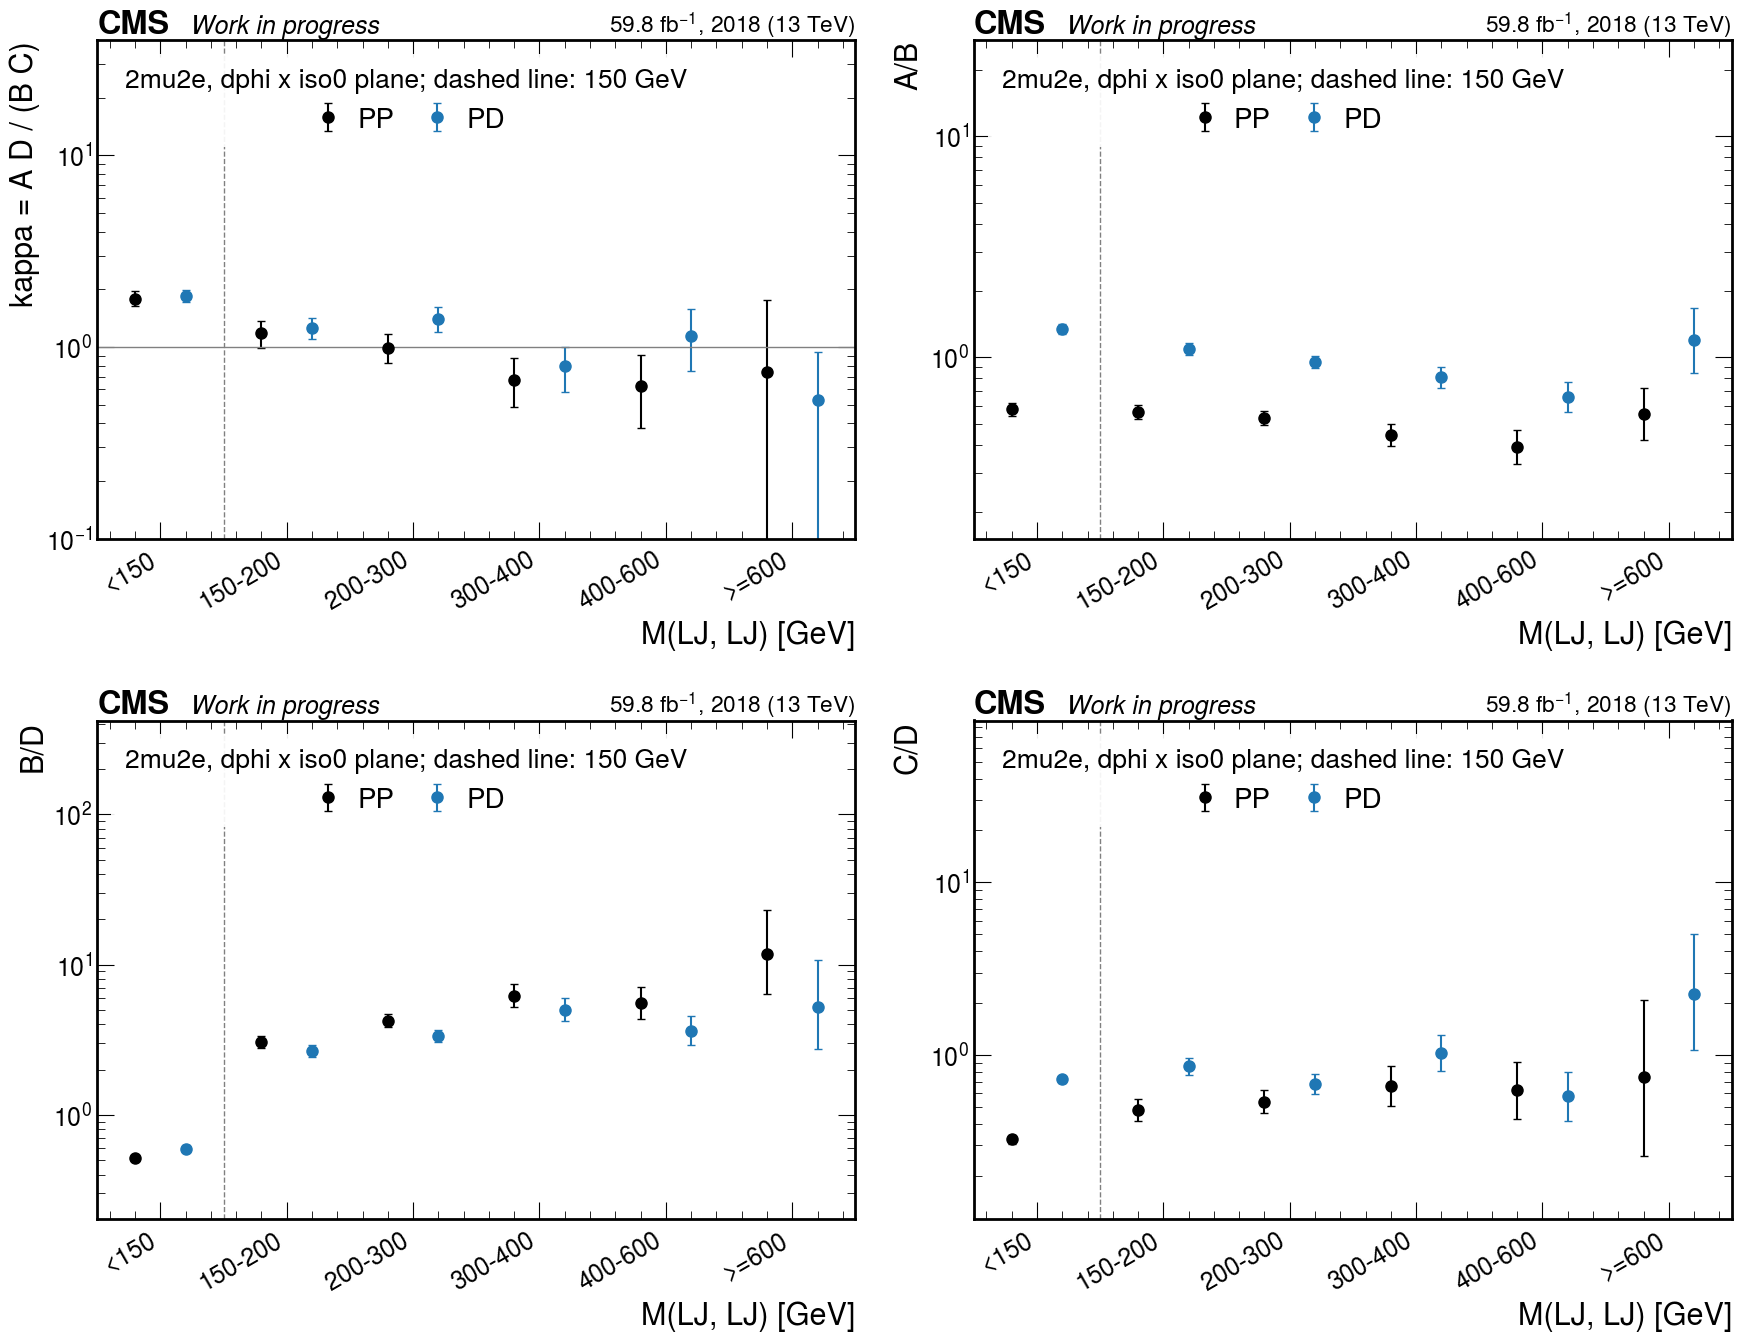

In [3]:
PROFILES2 = bl.signal_profiles(BASE, SIGNAL_POINTS["2mu2e"], "2mu2e", NOMINAL)     # A of DD, every mass
EDGES = PROFILES2[0]
DD_SIDEBANDS = {r: el.spectrum(d2, "ljlj_mass", NOMINAL, "DD", r)[1] for r in "BCD"}    # the open regions of DD
fig = bp.mass_shapes_figure(PROFILES2[1], DD_SIDEBANDS, EDGES)
plt.show()
for plane in ("DD", "PD", "PP"):
    print(f"2mu2e, {plane}: the regions per mass bin and DSA class of the muon LJ")
    display(bl.counts_table(d2, NOMINAL, bl.FIT_BINS, planes=(plane,)))
fig = pp.mass_figure(d2, planes=("PP", "PD"), cfg=NOMINAL)
plt.show()

## 3. A/B against the mass

The points of the fit are A/B per mass bin of the histograms above 150 GeV, per plane and DSA
class, at the mean mass of the plane's B events in the bin. The histograms store no mass inside a
bin, so each bin's events count at its centre and the overflow above 2500 GeV at 2500 GeV; the mass
of a point is known to about the width of its bin, and the last bin (≥ 1000 GeV) to a factor two.
Both forms are binomial-likelihood fits over all seven bins (introduction): the quality of a fit is
its deviance, twice the log-likelihood ratio of the data to the fit, which plays the part of χ² and
is distributed like it for large counts; a bin's residual is the signed square root of its share of
the deviance, positive where the measured A/B lies above the fit, and is defined also for a bin with
no A or no B event. The exponential is the nominal form, as fixed in the introduction.

The table gives per plane, class and form the parameters (the slope of the line per TeV, the scale
M₀ of the exponential) and the deviance over ndof, and per bin the measured A/B (a lower limit,
A/1.84, where B = 0), the fitted A/B and the residual. The figure draws the points and both curves
for PD and PP per class, with the 68% band of the nominal fit; an upward arrow is a bin without a
B event, drawn at its lower limit. Below it, the ratio of PP's A/B to PD's per bin and class with
its weighted mean: a flat ratio says that the trend does not change with the egamma LJ's state.
Over the whole window the ratio is 0.54 (797/1545 in PP against 1343/1401 in PD, all classes).
Whether the trend also holds for a displaced muon LJ is the B route's own assumption, which the
open tests of `estimate.ipynb` check over the whole window and section 4 checks per bin. The last
line gives the fall of PD's A/B between the first bin and the 400–600 GeV bin.

What the likelihood fit changed against the least-squares fit of the first version: the
least-squares fit used the five or six bins with both counts and read the exponential for PD's
dsa0 class as M₀ = 910 ± 344 GeV (χ²/ndof 5.5/4), 0.64 ± 0.12 at 700 GeV; the ≥ 1000 GeV bin, 4 A
and 0 B events, was not in it. The numbers below replace those.

A/B against the mass: the fit per plane, class and form, and the points against it


,plane,class,form,bin,parameters,deviance / ndof,M [GeV],A/B measured,A/B fitted,residual
0,PD,dsa0,linear,fit,"a = 1.085 ± 0.084, b = -0.164 ± 0.272 per TeV",19.5 / 5,,,,
1,PD,dsa0,linear,150-200,,,175,1.18 -0.07 +0.08,1.06 ± 0.05,+1.7
2,PD,dsa0,linear,200-300,,,250,1.02 -0.07 +0.07,1.04 ± 0.04,-0.3
3,PD,dsa0,linear,300-400,,,350,0.89 -0.10 +0.11,1.03 ± 0.05,-1.3
4,PD,dsa0,linear,400-600,,,500,0.70 -0.11 +0.13,1.00 ± 0.08,-2.4
5,PD,dsa0,linear,600-800,,,700,1.64 -0.59 +0.95,0.97 ± 0.12,+1.4
6,PD,dsa0,linear,800-1000,,,900,0.60 -0.38 +0.96,0.94 ± 0.18,-0.6
7,PD,dsa0,linear,>=1000,,,2125,>= 2.17 (4/0),0.74 ± 0.51,+2.6
8,PD,dsa0,exponential,fit,"a = 1.136 ± 0.103, M0 = 3027 ± 2831 GeV",18.9 / 5,,,,
9,PD,dsa0,exponential,150-200,,,175,1.18 -0.07 +0.08,1.07 ± 0.05,+1.5


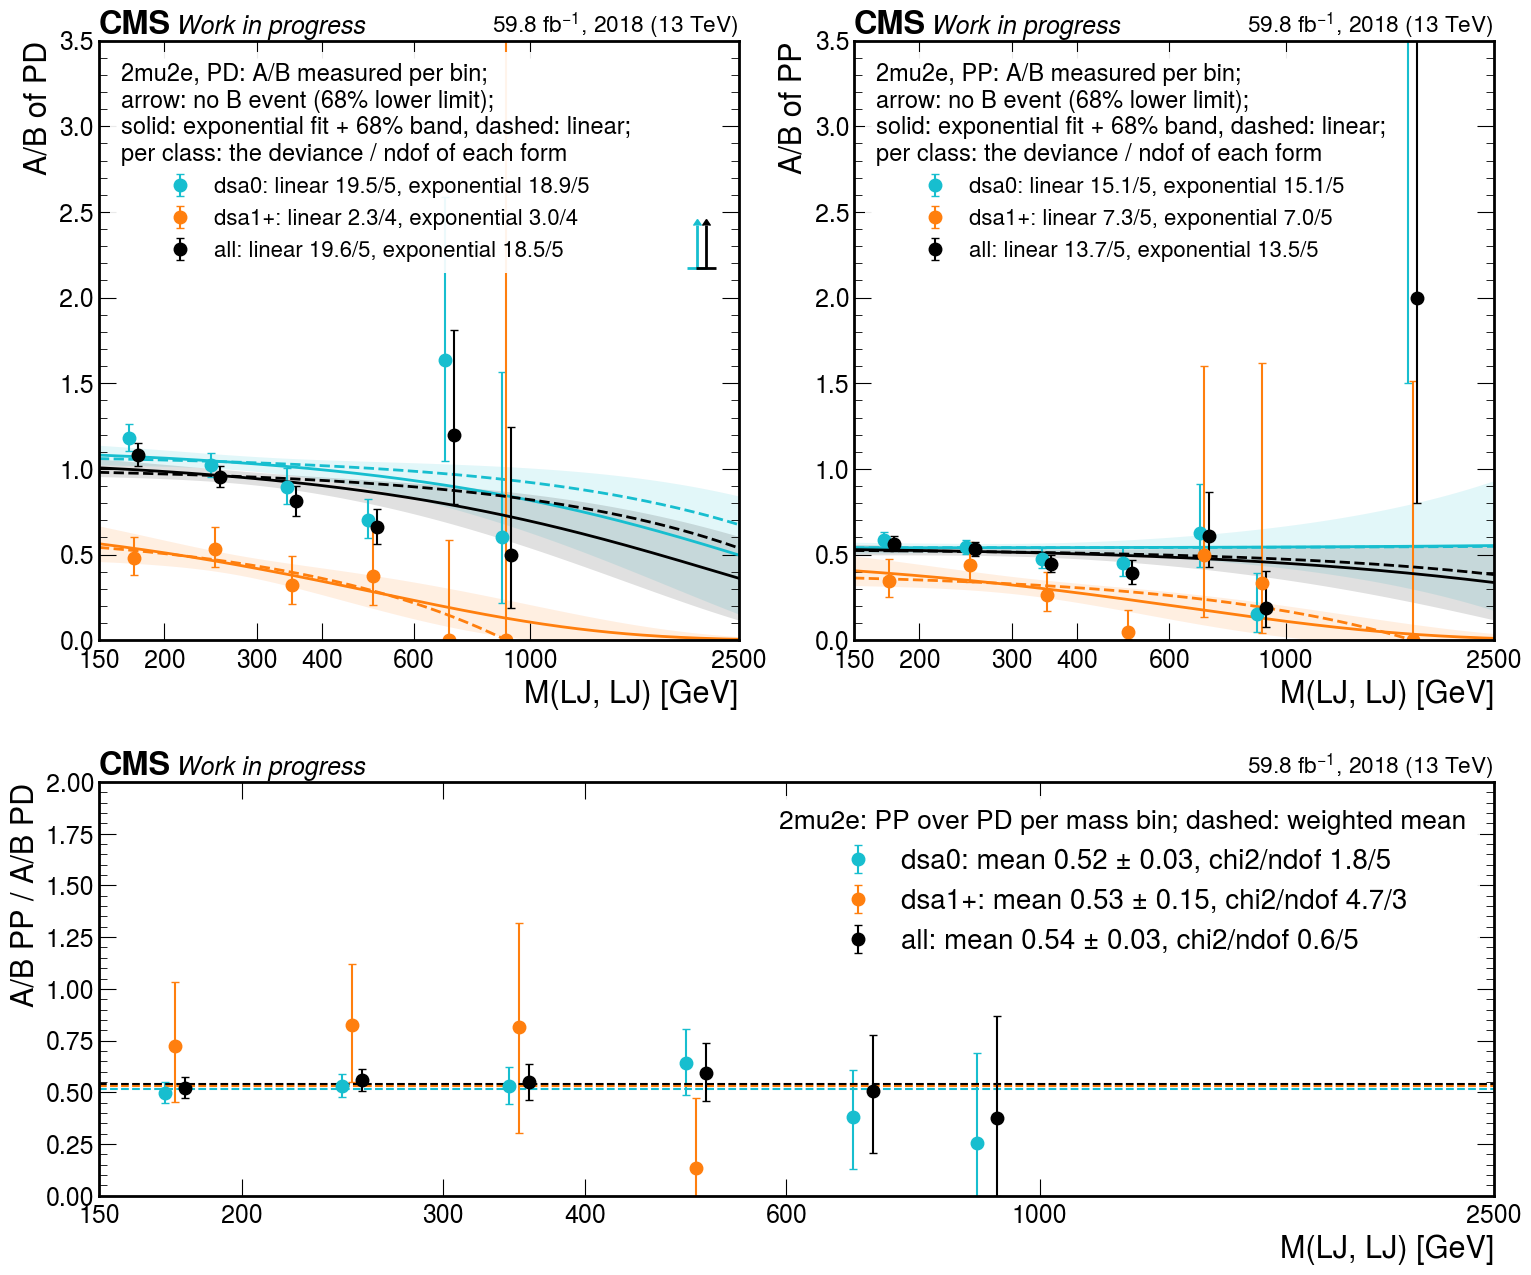

A/B of PP over A/B of PD per mass bin


,class,150-200,200-300,300-400,400-600,600-800,800-1000,>=1000,weighted mean,chi2 / ndof against it
0,dsa0,0.50 ± 0.05,0.53 ± 0.06,0.53 ± 0.09,0.64 ± 0.16,0.38 -0.25 +0.22,0.26 -0.26 +0.43,n/a,0.516 ± 0.033,1.8 / 5
1,dsa1+,0.72 -0.27 +0.31,0.82 -0.28 +0.29,0.82 ± 0.51,0.13 -0.13 +0.34,n/a,n/a,n/a,0.528 ± 0.147,4.7 / 3
2,all,0.52 ± 0.05,0.56 ± 0.06,0.55 ± 0.09,0.59 ± 0.14,0.51 -0.30 +0.27,0.38 -0.38 +0.49,n/a,0.542 ± 0.033,0.6 / 5


PD, all classes: A/B at 400-600 GeV over A/B at 150-200 GeV: 0.61 -0.10 +0.11


In [4]:
POINTS = {(p, c): bl.ab_points(d2, NOMINAL, bl.FIT_BINS, p, c) for p in ("PD", "PP") for c in ("dsa0", "dsa1+", None)}
FITS = {(p, c, f): bl.fit_ab(POINTS[(p, c)], f) for (p, c) in POINTS for f in bl.FORMS}
print("A/B against the mass: the fit per plane, class and form, and the points against it")
display(bl.ab_fit_table(d2, NOMINAL, bl.FIT_BINS))
fig = bp.ab_mass_figure(POINTS, FITS, band_form=FORM)
plt.show()
print("A/B of PP over A/B of PD per mass bin")
display(bl.plane_ratio_table(POINTS))
first, mid = (tuple(POINTS[("PD", None)].set_index("bin").loc[b, ["A/B", "minus", "plus"]]) for b in ("150-200", "400-600"))
print("PD, all classes: A/B at 400-600 GeV over A/B at 150-200 GeV:", tl.fmt(tl.ratio_of_ratios(mid, first), 2))

## 4. The estimate per bin

For each binning, the B route per bin and DSA class: B of DD and the mean mass of those events;
A/B of PD measured in the bin with its precision (the larger side of the 68% interval over the
value); the fitted A/B at the mean mass (nominal form); the estimate with the measured and with the
fitted factor; the factor the rule selects and the estimate with it; and the shape systematic,
|measured − fitted| over the selected estimate, with the part of it the selected estimate carries
(zero where the measured factor is taken). The "sum" rows add the two classes; the last row adds
the bins, in quadrature, which is exact for the measured factors and understates the error of
fitted ones (the bins share the fit's parameters).

The one-bin binning with the measured factor is the estimate of `estimate.ipynb`, 61.3 ± 8.0; the
two windows with the measured factors reproduce its per-window B route, 41 ± 7 at 150–300 GeV and
19 ± 4 above 300 GeV, which `estimate_lib.routes_table` repeats below the binned tables as the
check.

Then the sums over the bins against the one-bin estimate. With a factor that is the same at every
mass they would agree exactly. If A/B falls with the mass and the search plane's B events sit at
other masses than PD's, the binned sum moves away from the one-bin value: the difference is the
error the one-bin form makes by weighting PD's factor with PD's own mass distribution. The same
sums with the linear fit are the cross-check of the form.

The figure draws the selected background per bin of each binning with its statistical error
added in quadrature with the shape systematic it carries, the 33% systematic as a log-normal band
(the bin's value times and divided by 1.33, the toy's convention), and the yields per bin of the
points 500 GeV, 0.25 GeV, 0.4 mm and 800 GeV, 0.25 GeV, 0.25 mm at their stored cross sections;
the tables below it give every signal point's yield per bin.

**The open test per bin.** The same route can be run where its answer is observed: from PP into
DP, the muon LJ going from prompt to displaced with the egamma LJ prompt, the analog `estimate.ipynb`
section 3.1 uses over the whole window (observed over predicted 1.32 ± 0.27; 1.27 ± 0.33 at
150–300 GeV and 1.5 ± 0.5 above). The tables repeat it per bin of the cube bins and of the two
windows: B of DP, the predicted A of DP with the factor the rule selects (A/B of PP per class,
measured where PP measures it to 20%, fitted otherwise), the observed A of DP with its 68% Poisson
interval, and their ratio. The last column is the systematic the recipe of `estimate.ipynb` would
assign to the bin from this test alone, |ratio − 1| plus the precision of the ratio; section 5 uses
it as the third reading of the systematic. DP's A holds signal too (the next table), so a ratio
above one is not only non-closure.

**Signal in the regions the estimate reads from.** Per bin of the cube bins, the yield of each
signal point at μ = 1 in A and B of PD per DSA class and in B of DD, next to the data counts: where
the signal's share of a region is large, the factor measured there — and the shape systematic built
from it — would move if the signal exists at that strength.

one bin (exponential fit)


,bin,class,B DD,mean M of B DD [GeV],A/B PD measured (precision),A/B PD fitted,"estimate, measured A/B","estimate, fitted A/B",choice,"estimate, selected",|measured - fitted| / selected,shape systematic carried
0,>=150,dsa0,44,312,1.04 ± 0.04 (4%),1.02 ± 0.04,45.8 ± 7.2,45.1 ± 7.1,measured,45.8 ± 7.2,2%,0%
1,>=150,dsa1+,34,265,0.45 -0.06 +0.07 (14%),0.45 ± 0.06,15.5 ± 3.5,15.3 ± 3.3,measured,15.5 ± 3.5,1%,0%
2,>=150,sum,78,292,,,61.3 ± 8.0,60.3 ± 7.8,measured,61.3 ± 8.0,1%,0%
3,sum over bins,sum,78,292,,,61.3 ± 8.0,60.3 ± 7.8,,61.3 ± 8.0,,


two windows (exponential fit)


,bin,class,B DD,mean M of B DD [GeV],A/B PD measured (precision),A/B PD fitted,"estimate, measured A/B","estimate, fitted A/B",choice,"estimate, selected",|measured - fitted| / selected,shape systematic carried
0,150-300,dsa0,25,205,1.10 ± 0.05 (5%),1.06 ± 0.05,27.5 ± 5.7,26.5 ± 5.4,measured,27.5 ± 5.7,4%,0%
1,150-300,dsa1+,27,214,0.51 -0.07 +0.08 (16%),0.50 ± 0.07,13.7 -3.3 +3.5,13.4 ± 3.2,measured,13.7 -3.3 +3.5,2%,0%
2,150-300,sum,52,210,,,41.2 ± 6.6,39.9 ± 6.3,measured,41.2 ± 6.6,2%,0%
3,>=300,dsa0,19,453,0.86 -0.07 +0.08 (9%),0.98 ± 0.07,16.4 ± 4.1,18.6 ± 4.5,measured,16.4 ± 4.1,13%,0%
4,>=300,dsa1+,7,464,0.31 -0.09 +0.12 (38%),0.30 ± 0.09,2.2 -1.0 +1.2,2.1 ± 1.0,fitted,2.1 ± 1.0,1%,1%
5,>=300,sum,26,456,,,18.6 ± 4.2,20.7 ± 4.6,"dsa0 measured, dsa1+ fitted",18.5 ± 4.2,12%,0%
6,sum over bins,sum,78,292,,,59.8 ± 7.9,60.6 ± 7.8,,59.7 ± 7.8,,


cube bins (exponential fit)


...

,window,DD B/C/D,B x A/B per class
0,M >= 150,78/17/29,61.3 ± 8.0
1,150-300,52/11/26,41.2 ± 6.6
2,M >= 300,26/6/3,18.6 ± 4.2


the sums over the bins (exponential fit) against the one-bin estimate with the measured A/B


,binning,bins,B of the search plane,"sum, measured A/B","sum, fitted A/B","sum, selected",selected / one bin (measured)
0,one bin,1,78,61.3 ± 8.0,60.3 ± 7.8,61.3 ± 8.0,1.000
1,two windows,2,78,59.8 ± 7.9,60.6 ± 7.8,59.7 ± 7.8,0.975
2,cube bins,5,78,61.5 ± 8.5,60.8 ± 7.6,59.4 ± 7.6,0.969
3,three bins,3,78,61.1 ± 8.4,60.7 ± 7.7,59.2 ± 7.8,0.967


the same with the linear fit


,binning,bins,B of the search plane,"sum, measured A/B","sum, fitted A/B","sum, selected",selected / one bin (measured)
0,one bin,1,78,61.3 ± 8.0,61.1 ± 7.9,61.3 ± 8.0,1.000
1,two windows,2,78,59.8 ± 7.9,61.1 ± 7.8,59.8 ± 7.8,0.976
2,cube bins,5,78,61.5 ± 8.5,61.1 ± 7.6,59.5 ± 7.6,0.972
3,three bins,3,78,61.1 ± 8.4,61.1 ± 7.7,59.5 ± 7.8,0.971


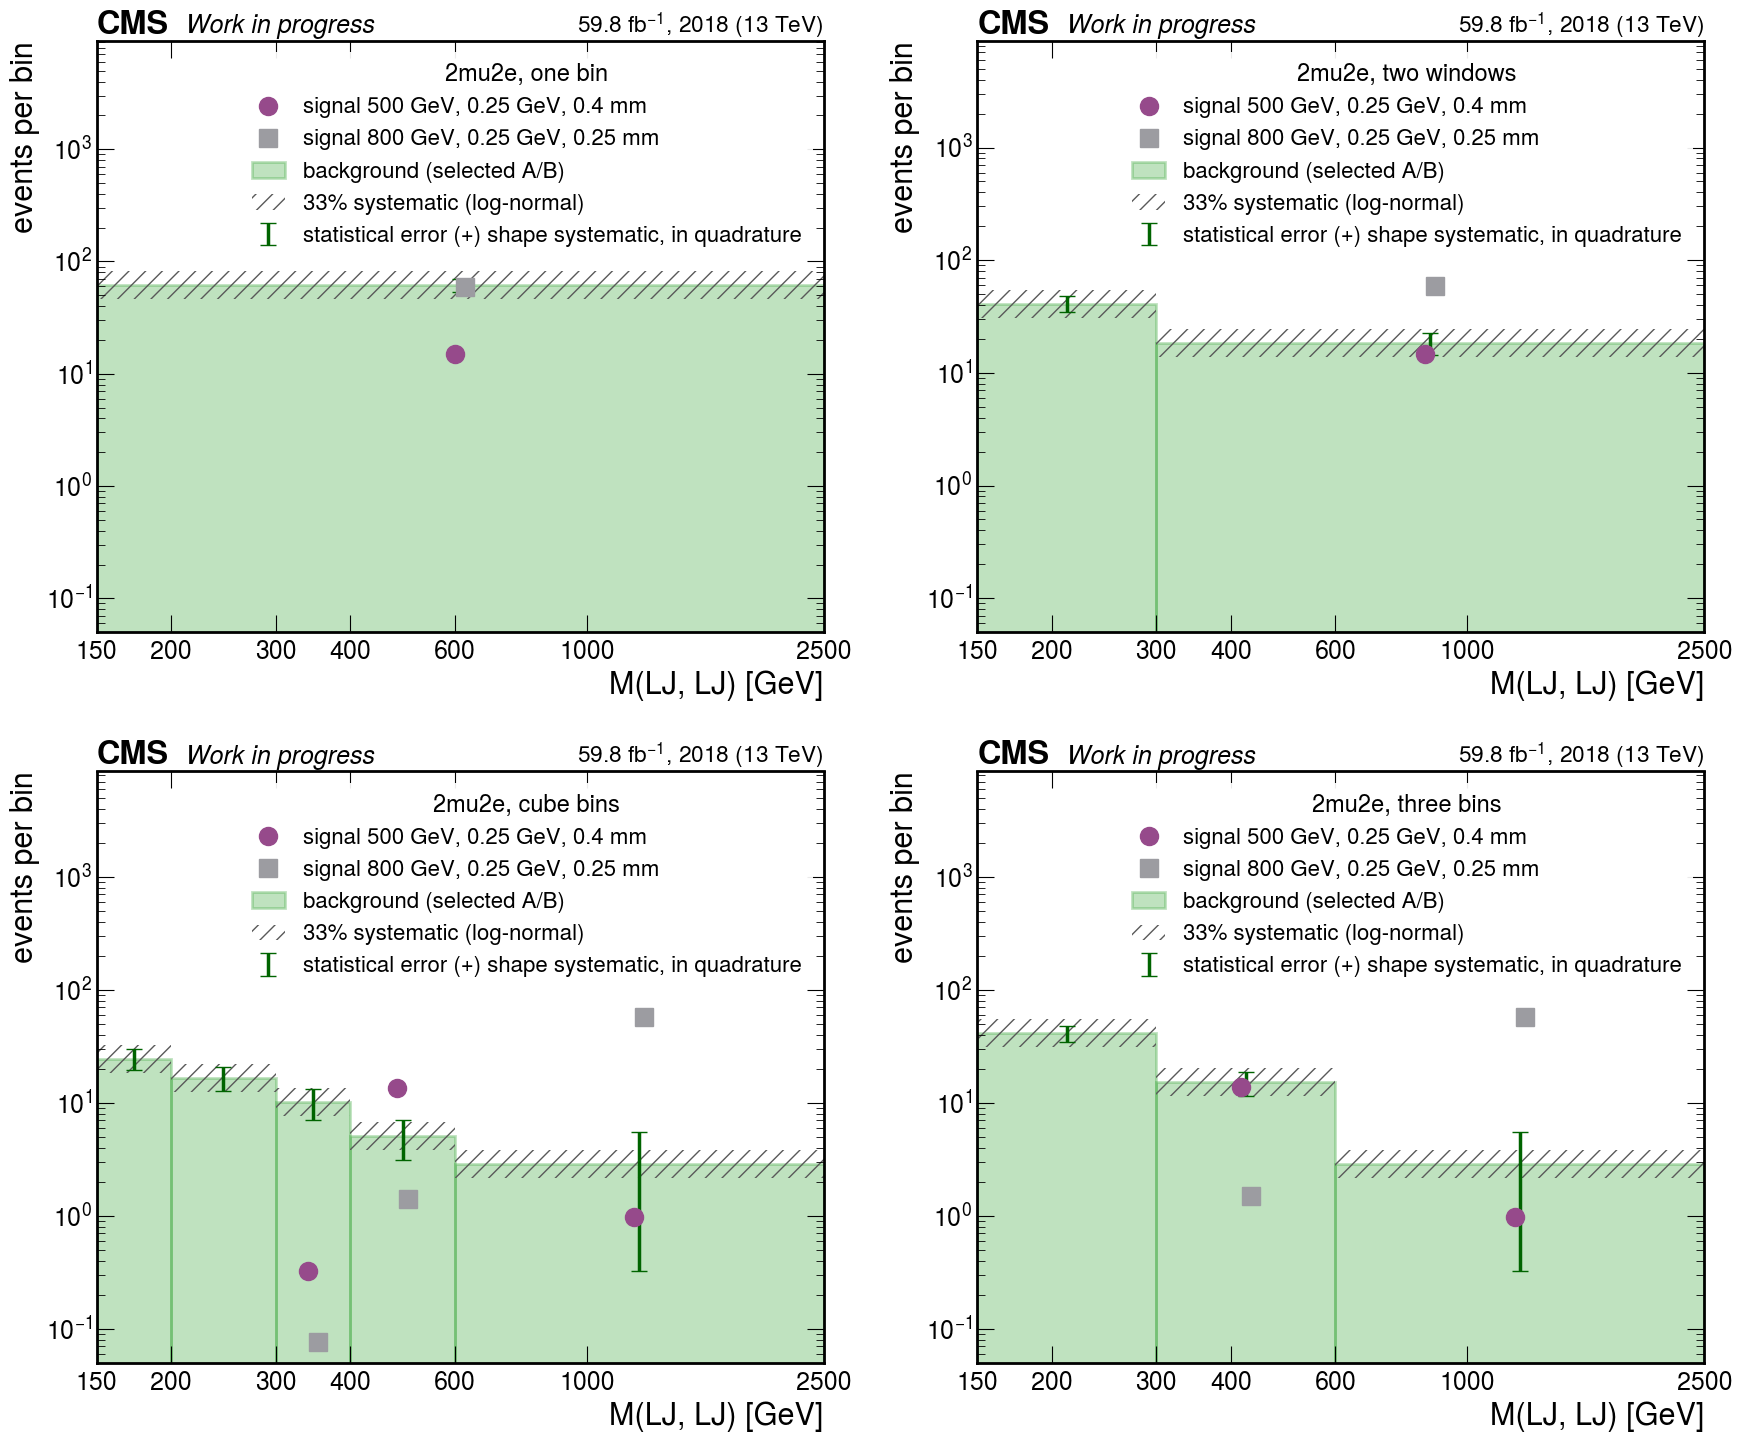

signal in A of DD per bin at the stored cross section, one bin


,point,>=150,sum
0,2Mu2E_200GeV_0p25GeV_1p0mm,0.56,0.56
1,2Mu2E_500GeV_0p25GeV_0p4mm,14.86,14.86
2,2Mu2E_800GeV_0p25GeV_0p25mm,58.85,58.85
3,2Mu2E_1000GeV_0p25GeV_0p2mm,1.48,1.48
4,2Mu2E_800GeV_1p2GeV_1p2mm,63.10,63.10
5,2Mu2E_1000GeV_1p2GeV_0p96mm,2.05,2.05
6,2Mu2E_800GeV_0p25GeV_1p2mm,21.48,21.48


signal in A of DD per bin at the stored cross section, two windows


,point,150-300,>=300,sum
0,2Mu2E_200GeV_0p25GeV_1p0mm,0.56,0.00,0.56
1,2Mu2E_500GeV_0p25GeV_0p4mm,0.02,14.84,14.86
2,2Mu2E_800GeV_0p25GeV_0p25mm,0.03,58.82,58.85
3,2Mu2E_1000GeV_0p25GeV_0p2mm,0.00,1.48,1.48
4,2Mu2E_800GeV_1p2GeV_1p2mm,0.06,63.05,63.10
5,2Mu2E_1000GeV_1p2GeV_0p96mm,0.00,2.05,2.05
6,2Mu2E_800GeV_0p25GeV_1p2mm,0.02,21.47,21.48


signal in A of DD per bin at the stored cross section, cube bins


...

,bin,B DP,choice,"predicted A DP (B x A/B PP, selected)",observed A DP,observed / predicted,|ratio - 1| + precision
0,150-200,22,"dsa0 measured, dsa1+ fitted",11.5 ± 2.7,13,1.13 -0.40 +0.48,56%
1,200-300,25,"dsa0 measured, dsa1+ fitted",10.7 ± 2.4,16,1.50 -0.50 +0.58,89%
2,300-400,9,"dsa0 measured, dsa1+ fitted",3.7 ± 1.3,6,1.60 -0.85 +1.11,130%
3,400-600,16,"dsa0 measured, dsa1+ fitted",5.9 ± 1.8,6,1.01 -0.51 +0.67,68%
4,>=600,3,fitted,0.3 -0.3 +1.1,3,9.74 -9.74 +13.59,1014%
5,sum over bins,75,,32.2 ± 4.3,44,1.37 -0.28 +0.30,59%


the open test per bin: the B route from PP into DP against the observed A of DP, two windows


,bin,B DP,choice,"predicted A DP (B x A/B PP, selected)",observed A DP,observed / predicted,|ratio - 1| + precision
0,150-300,47,"dsa0 measured, dsa1+ fitted",22.0 ± 3.6,29,1.32 -0.33 +0.36,59%
1,>=300,28,"dsa0 measured, dsa1+ fitted",10.1 ± 2.4,15,1.48 -0.51 +0.60,88%
2,sum over bins,75,,32.2 ± 4.3,44,1.37 -0.28 +0.30,59%


signal at mu = 1 in the regions the estimate reads from, per bin of the cube bins, next to the data


,point,region,150-200,200-300,300-400,400-600,>=600,sum
0,data,A PD:dsa0,539,455,161,73,25,1253
1,data,B PD:dsa0,457,446,180,104,16,1203
2,data,A PD:dsa1+,35,39,10,6,0,90
3,data,B PD:dsa1+,73,73,31,16,5,198
4,data,B DD,28,24,13,9,4,78
5,2Mu2E_200GeV_0p25GeV_1p0mm,A PD:dsa0,0.06,0.06,0.00,0.00,0.00,0.12
6,2Mu2E_200GeV_0p25GeV_1p0mm,B PD:dsa0,0.00,0.00,0.00,0.00,0.00,0.00
7,2Mu2E_200GeV_0p25GeV_1p0mm,A PD:dsa1+,0.01,0.01,0.00,0.00,0.00,0.01
8,2Mu2E_200GeV_0p25GeV_1p0mm,B PD:dsa1+,0.00,0.00,0.00,0.00,0.00,0.00
9,2Mu2E_200GeV_0p25GeV_1p0mm,B DD,0.00,0.00,0.00,0.00,0.00,0.01


In [5]:
FIT = {("PD", c): FITS[("PD", c, FORM)] for c in bl.CLASSES}
ROUTES = {name: bl.binned_routes(d2, NOMINAL, bins, fits=FIT) for name, bins in bl.BINNINGS.items()}
for name, routes in ROUTES.items():
    print(f"{name} ({FORM} fit)")
    display(bl.routes_view(routes))
print("the B route per window of estimate.ipynb")
display(el.routes_table(d2, WINDOWS)[["window", "DD B/C/D", "B x A/B per class"]])
print(f"the sums over the bins ({FORM} fit) against the one-bin estimate with the measured A/B")
display(bl.sums_table(ROUTES))
FIT_LINEAR = {("PD", c): FITS[("PD", c, "linear")] for c in bl.CLASSES}
ROUTES_LINEAR = {name: bl.binned_routes(d2, NOMINAL, bins, fits=FIT_LINEAR) for name, bins in bl.BINNINGS.items()}
print("the same with the linear fit")
display(bl.sums_table(ROUTES_LINEAR))
YIELDS2 = {name: bl.signal_yields(BASE, SIGNAL_POINTS["2mu2e"], "2mu2e", NOMINAL, bins, profiles=PROFILES2)
           for name, bins in bl.BINNINGS.items()}
fig = bp.binning_figure(ROUTES, YIELDS2, syst_rel=SYST)
plt.show()
for name, yields in YIELDS2.items():
    print(f"signal in A of DD per bin at the stored cross section, {name}")
    display(bl.yields_view(yields))
FIT_PP = {("PP", c): FITS[("PP", c, FORM)] for c in bl.CLASSES}
OPEN = {name: bl.open_test_table(d2, NOMINAL, bins, fits=FIT_PP) for name, bins in bl.BINNINGS.items()}
for name in ("cube bins", "two windows"):
    print(f"the open test per bin: the B route from PP into DP against the observed A of DP, {name}")
    display(OPEN[name].drop(columns=["ratio", "ratio minus", "ratio plus", "syst"]))
print("signal at mu = 1 in the regions the estimate reads from, per bin of the cube bins, next to the data")
display(bl.signal_regions_table(BASE, SIGNAL_POINTS["2mu2e"], "2mu2e", NOMINAL, bl.BINNINGS["cube bins"], data=d2))

## 5. The toy expected limit and the choice of binning

The toy is a counting experiment per bin. The background is the estimate of the bin (selected,
measured or fitted factor), with its statistical error and the shape systematic it carries as an
independent log-normal nuisance per bin and the 33% systematic as one log-normal nuisance common to
all bins; the signal per bin is the point's yield in A of DD at its stored cross section. The limit
is the median expected 95% CL CLs upper limit in the asymptotic approximation (Cowan, Cranmer,
Gross, Vitells, Eur. Phys. J. C 71 (2011) 1554; what combine's AsymptoticLimits gives for such a
datacard). The tables give per signal point the one-bin limit in signal events (measured factor)
and each binning's limit relative to it; below one is a gain.

**Caveat.** The toy is an asymptotic counting approximation with no signal systematics, and it is
used only for relative comparisons between binnings; its absolute limits are not the analysis's. It
is optimistic for bins with less than about one background event (with no background it gives 1.9
signal events against the exact 3.0), and it treats the errors of fitted estimates as independent
per bin although the bins share the fit's parameters.

**The common systematic.** With one systematic nuisance for all bins, a bin without signal —
150–300 GeV for the heavy points — constrains it for the others; a datacard with one log-normal
line across the bins does the same. That is right only if the non-closure is the same in every bin.
κ of PP and PD fall by about two standard deviations between 150–300 GeV and M ≥ 300 GeV in
`estimate.ipynb`, so the limits are repeated with an independent 33% per bin, and once more with an
independent systematic per bin sized by the open test of that bin (section 4: |observed/predicted
− 1| plus the precision of the ratio, the recipe of `estimate.ipynb` applied bin by bin, which is
mostly the precision of a few DP events). The rule is applied to the common form, the toy as
defined; the two other forms show how much of the gain rests on that constraint and on the size of
the systematic.

The decision table checks each binning against the rule's count requirement — every bin with at
least 5 B events of DD or an estimate below 3 events — and lists where the fitted factor is taken
and the largest shape systematic. The rule table applies the rule: the eligible binnings, the
relative limit of the decision points per mass, their mean, and the binning chosen. It is repeated
with the independent systematic, with the per-bin systematic from the open test, and with the
linear fit.

expected limit relative to one bin, measured A/B, systematic common to all bins


,point,"one bin, measured A/B [events]",one bin,two windows,cube bins,three bins
0,2Mu2E_200GeV_0p25GeV_1p0mm,33.3,1.000,0.669,0.649,0.667
1,2Mu2E_500GeV_0p25GeV_0p4mm,33.3,1.000,0.380,0.219,0.362
2,2Mu2E_800GeV_0p25GeV_0p25mm,33.3,1.000,0.379,0.206,0.206
3,2Mu2E_1000GeV_0p25GeV_0p2mm,33.3,1.000,0.379,0.202,0.202
4,2Mu2E_800GeV_1p2GeV_1p2mm,33.3,1.000,0.379,0.208,0.208
5,2Mu2E_1000GeV_1p2GeV_0p96mm,33.3,1.000,0.379,0.205,0.205
6,2Mu2E_800GeV_0p25GeV_1p2mm,33.3,1.000,0.379,0.208,0.208


expected limit relative to one bin, fitted A/B, systematic common to all bins


,point,"one bin, measured A/B [events]",one bin,two windows,cube bins,three bins
0,2Mu2E_200GeV_0p25GeV_1p0mm,33.3,0.987,0.653,0.629,0.655
1,2Mu2E_500GeV_0p25GeV_0p4mm,33.3,0.987,0.415,0.249,0.409
2,2Mu2E_800GeV_0p25GeV_0p25mm,33.3,0.987,0.414,0.166,0.166
3,2Mu2E_1000GeV_0p25GeV_0p2mm,33.3,0.987,0.414,0.163,0.163
4,2Mu2E_800GeV_1p2GeV_1p2mm,33.3,0.987,0.415,0.168,0.168
5,2Mu2E_1000GeV_1p2GeV_0p96mm,33.3,0.987,0.414,0.165,0.165
6,2Mu2E_800GeV_0p25GeV_1p2mm,33.3,0.987,0.414,0.168,0.168


expected limit relative to one bin, selected A/B, systematic common to all bins


,point,"one bin, measured A/B [events]",one bin,two windows,cube bins,three bins
0,2Mu2E_200GeV_0p25GeV_1p0mm,33.3,1.000,0.669,0.638,0.670
1,2Mu2E_500GeV_0p25GeV_0p4mm,33.3,1.000,0.379,0.212,0.359
2,2Mu2E_800GeV_0p25GeV_0p25mm,33.3,1.000,0.379,0.166,0.166
3,2Mu2E_1000GeV_0p25GeV_0p2mm,33.3,1.000,0.378,0.163,0.163
4,2Mu2E_800GeV_1p2GeV_1p2mm,33.3,1.000,0.379,0.168,0.168
5,2Mu2E_1000GeV_1p2GeV_0p96mm,33.3,1.000,0.378,0.165,0.165
6,2Mu2E_800GeV_0p25GeV_1p2mm,33.3,1.000,0.379,0.168,0.168


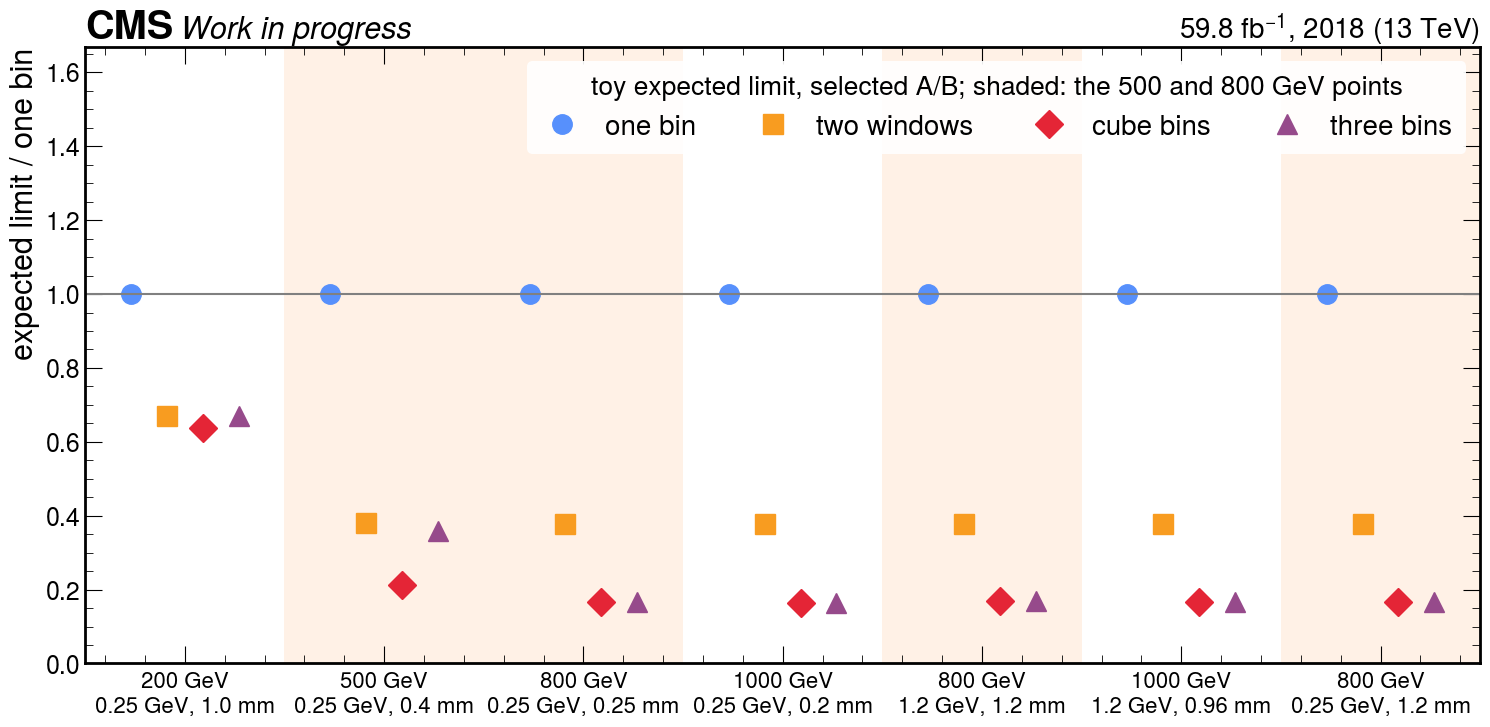

the same, selected A/B, with an independent systematic per bin


,point,"one bin, measured A/B [events]",one bin,two windows,cube bins,three bins
0,2Mu2E_200GeV_0p25GeV_1p0mm,33.3,1.000,0.740,0.626,0.740
1,2Mu2E_500GeV_0p25GeV_0p4mm,33.3,1.000,0.417,0.218,0.386
2,2Mu2E_800GeV_0p25GeV_0p25mm,33.3,1.000,0.416,0.168,0.168
3,2Mu2E_1000GeV_0p25GeV_0p2mm,33.3,1.000,0.416,0.165,0.165
4,2Mu2E_800GeV_1p2GeV_1p2mm,33.3,1.000,0.417,0.169,0.169
5,2Mu2E_1000GeV_1p2GeV_0p96mm,33.3,1.000,0.416,0.167,0.167
6,2Mu2E_800GeV_0p25GeV_1p2mm,33.3,1.000,0.417,0.169,0.169


the per-bin systematic from the open test, per binning: {'one bin': ['54%'], 'two windows': ['59%', '88%'], 'cube bins': ['56%', '89%', '130%', '68%', '1014%'], 'three bins': ['59%', '67%', '1014%']}


the same, selected A/B, with an independent systematic per bin sized by the open test of the bin


,point,"one bin, measured A/B [events]",one bin,two windows,cube bins,three bins
0,2Mu2E_200GeV_0p25GeV_1p0mm,40.8,1.000,0.743,0.651,0.743
1,2Mu2E_500GeV_0p25GeV_0p4mm,40.8,1.000,0.436,0.192,0.373
2,2Mu2E_800GeV_0p25GeV_0p25mm,40.8,1.000,0.436,0.169,0.169
3,2Mu2E_1000GeV_0p25GeV_0p2mm,40.8,1.000,0.436,0.165,0.165
4,2Mu2E_800GeV_1p2GeV_1p2mm,40.8,1.000,0.436,0.170,0.170
5,2Mu2E_1000GeV_1p2GeV_0p96mm,40.8,1.000,0.436,0.168,0.168
6,2Mu2E_800GeV_0p25GeV_1p2mm,40.8,1.000,0.436,0.170,0.170


...

,binning,eligible,500 GeV,800 GeV,mean over the masses,chosen
0,one bin,True,1.000,1.000,1.000,False
1,two windows,True,0.417,0.417,0.417,False
2,cube bins,True,0.218,0.169,0.193,True
3,three bins,True,0.386,0.169,0.277,False


the same with the per-bin systematic from the open test


,binning,eligible,500 GeV,800 GeV,mean over the masses,chosen
0,one bin,True,1.000,1.000,1.000,False
1,two windows,True,0.436,0.436,0.436,False
2,cube bins,True,0.192,0.170,0.181,True
3,three bins,True,0.373,0.170,0.271,False


the same with the linear fit


,binning,eligible,500 GeV,800 GeV,mean over the masses,chosen
0,one bin,True,1.000,1.000,1.000,False
1,two windows,True,0.379,0.379,0.379,True
2,cube bins,False,0.212,0.170,0.191,False
3,three bins,False,0.360,0.170,0.265,False


In [6]:
LIMITS = bl.limit_table(ROUTES, YIELDS2, syst_rel=SYST)
for factor in bl.FACTORS:
    print(f"expected limit relative to one bin, {factor} A/B, systematic common to all bins")
    display(bl.limit_view(LIMITS, factor))
fig = bp.limit_figure(LIMITS, "selected")
plt.show()
LIMITS_SEPARATE = bl.limit_table(ROUTES, YIELDS2, syst_rel=SYST, common=False)
print("the same, selected A/B, with an independent systematic per bin")
display(bl.limit_view(LIMITS_SEPARATE, "selected"))
OPEN_SYST = bl.open_test_syst(OPEN)
print("the per-bin systematic from the open test, per binning:", {k: [f"{v:.0%}" for v in a] for k, a in OPEN_SYST.items()})
LIMITS_OPEN = bl.limit_table(ROUTES, YIELDS2, syst_rel=OPEN_SYST, common=False)
print("the same, selected A/B, with an independent systematic per bin sized by the open test of the bin")
display(bl.limit_view(LIMITS_OPEN, "selected"))
DECISION = bl.decision_table(ROUTES)
print("the count requirement of the rule per binning")
display(DECISION)
RULE = bl.rule_table(LIMITS, DECISION)
print("the rule: the decision points' limits relative to one bin (selected A/B, common systematic), each mass counted once")
display(RULE.round(3))
print("chosen:", ", ".join(RULE.loc[RULE["chosen"], "binning"]) or "none")
print("the same with an independent systematic per bin")
display(bl.rule_table(LIMITS_SEPARATE, DECISION).round(3))
print("the same with the per-bin systematic from the open test")
display(bl.rule_table(LIMITS_OPEN, DECISION).round(3))
print("the same with the linear fit")
display(bl.rule_table(bl.limit_table(ROUTES_LINEAR, YIELDS2, syst_rel=SYST), bl.decision_table(ROUTES_LINEAR)).round(3))

## 6. 4μ

In 4μ both objects are muon LJs, and A of DD, DP and PD is hidden above 150 GeV (the figure below
is the cartoon of section 1 for 4μ). The search plane's sidebands hold three events above 150 GeV,
all in B, so its estimate is count-limited: about 1.7 events, uncertain by a factor two to three
(`estimate.ipynb` section 5.2, from B of DD times A/B of the open planes). That sits at the Poisson
floor of a limit: with no background at all a 95% CL limit needs 3 signal events, and over an
expected background of 0.5 to 4 events the limit for one observed event moves only between 4.4 and
3.5.

Per mass bin the picture is sharper than in 2μ2e but gains less. The tables below give the counts
per mass bin of the four planes and the signal yields per bin of each binning. The three B events
of DD sit at 200–300 GeV (two) and 400–600 GeV (one); none lies above 600 GeV, where the 800 and
1000 GeV points have 83–95% of their yield, and the one event at 400–600 GeV shares its bin with
81% of the 500 GeV point's. The only open A/B above 150 GeV is PP's (0.81, 0.71, 0.47 and
0.17 −0.14 +0.50 in the four bins up to 600 GeV, 2/1 events above), so a per-bin route reads
1.4 events at 200–300 GeV, 0.2 at 400–600 GeV and none above 600 GeV, on two, one and no B
events. The heavy points' bins are therefore empty of background up to a 68% upper limit of
1.84 events times a factor that three PP events cannot fix, and binning gains 4μ at most the step
from a background of 1.7 to none — from roughly 4 to 3 signal events — a factor 1.3 against the
factor 2.6 to 6 of 2μ2e's heavy points (section 7). The toy of section 5 is not run for 4μ: below
one background event it is 1.9 signal events against the exact 3.0, and no 4μ bin holding the
heavy points' signal reaches one background event.

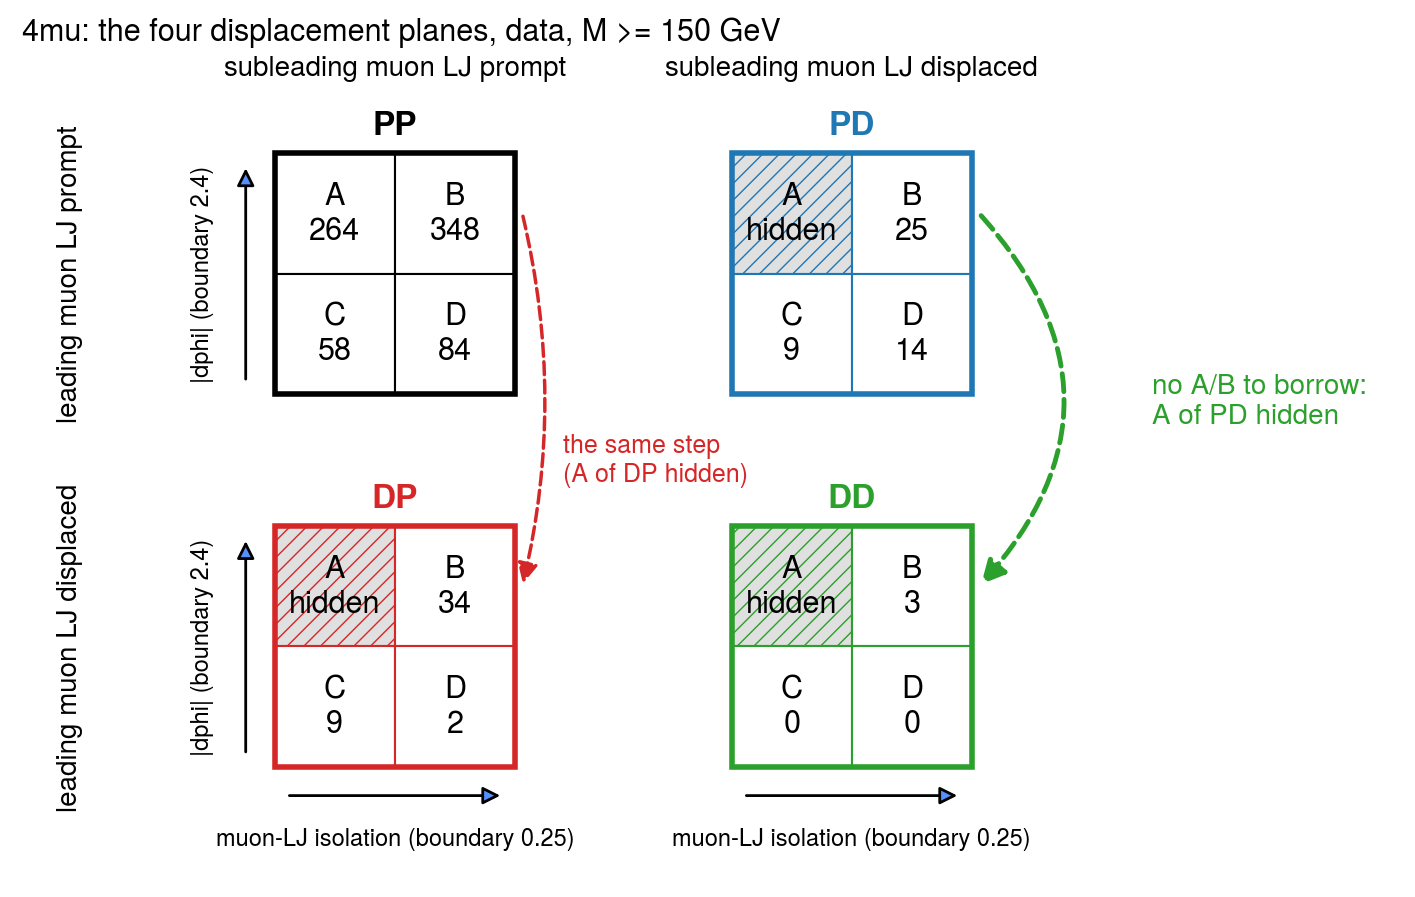

4mu: the regions per mass bin and plane (A of DD, DP and PD hidden)


,bin,plane,class,A,B,C,D,A/B,C/D,kappa
0,150-200,DD,all,blind,0,0,0,blind,n/a,blind
1,150-200,DP,all,blind,14,6,2,blind,3.00 -1.96 +7.07,blind
2,150-200,PD,all,blind,17,6,6,blind,1.00 -0.52 +1.09,blind
3,150-200,PP,all,180,221,38,40,0.81 -0.08 +0.09,0.95 -0.21 +0.27,0.86 ± 0.23
4,200-300,DD,all,blind,2,0,0,blind,n/a,blind
5,200-300,DP,all,blind,17,1,0,blind,n/a,blind
6,200-300,PD,all,blind,6,3,7,blind,0.43 -0.26 +0.61,blind
7,200-300,PP,all,73,103,16,36,0.71 -0.11 +0.13,0.44 -0.13 +0.18,1.59 -0.57 +0.67
8,300-400,DD,all,blind,0,0,0,blind,n/a,blind
9,300-400,DP,all,blind,1,2,0,blind,n/a,blind


4mu signal in A of DD per bin at the stored cross section, one bin


,point,>=150,sum
0,4Mu_200GeV_0p25GeV_1p0mm,0.94,0.94
1,4Mu_500GeV_0p25GeV_0p4mm,15.34,15.34
2,4Mu_800GeV_0p25GeV_0p25mm,50.73,50.73
3,4Mu_1000GeV_0p25GeV_0p2mm,1.17,1.17
4,4Mu_800GeV_1p2GeV_1p2mm,81.48,81.48
5,4Mu_1000GeV_1p2GeV_0p96mm,2.44,2.44
6,4Mu_800GeV_0p25GeV_1p2mm,13.57,13.57


4mu signal in A of DD per bin at the stored cross section, two windows


,point,150-300,>=300,sum
0,4Mu_200GeV_0p25GeV_1p0mm,0.93,0.02,0.94
1,4Mu_500GeV_0p25GeV_0p4mm,0.23,15.11,15.34
2,4Mu_800GeV_0p25GeV_0p25mm,0.15,50.58,50.73
3,4Mu_1000GeV_0p25GeV_0p2mm,0.00,1.17,1.17
4,4Mu_800GeV_1p2GeV_1p2mm,0.91,80.56,81.48
5,4Mu_1000GeV_1p2GeV_0p96mm,0.02,2.42,2.44
6,4Mu_800GeV_0p25GeV_1p2mm,0.12,13.45,13.57


4mu signal in A of DD per bin at the stored cross section, cube bins


,point,150-200,200-300,300-400,400-600,>=600,sum
0,4Mu_200GeV_0p25GeV_1p0mm,0.43,0.50,0.01,0.00,0.00,0.94
1,4Mu_500GeV_0p25GeV_0p4mm,0.01,0.22,1.17,12.43,1.52,15.34
2,4Mu_800GeV_0p25GeV_0p25mm,0.01,0.15,0.49,4.93,45.16,50.73
3,4Mu_1000GeV_0p25GeV_0p2mm,0.00,0.00,0.01,0.05,1.11,1.17
4,4Mu_800GeV_1p2GeV_1p2mm,0.07,0.84,1.94,7.18,71.44,81.48
5,4Mu_1000GeV_1p2GeV_0p96mm,0.00,0.01,0.04,0.15,2.23,2.44
6,4Mu_800GeV_0p25GeV_1p2mm,0.02,0.10,0.31,1.91,11.24,13.57


4mu signal in A of DD per bin at the stored cross section, three bins


,point,150-300,300-600,>=600,sum
0,4Mu_200GeV_0p25GeV_1p0mm,0.93,0.01,0.00,0.94
1,4Mu_500GeV_0p25GeV_0p4mm,0.23,13.59,1.52,15.34
2,4Mu_800GeV_0p25GeV_0p25mm,0.15,5.42,45.16,50.73
3,4Mu_1000GeV_0p25GeV_0p2mm,0.00,0.06,1.11,1.17
4,4Mu_800GeV_1p2GeV_1p2mm,0.91,9.12,71.44,81.48
5,4Mu_1000GeV_1p2GeV_0p96mm,0.02,0.19,2.23,2.44
6,4Mu_800GeV_0p25GeV_1p2mm,0.12,2.21,11.24,13.57


In [7]:
fig = bp.planes_cartoon(d4, NOMINAL, "4mu")
plt.show()
print("4mu: the regions per mass bin and plane (A of DD, DP and PD hidden)")
display(bl.counts_table(d4, NOMINAL, bl.FIT_BINS, planes=("DD", "DP", "PD", "PP"), classes=(None,)))
PROFILES4 = bl.signal_profiles(BASE, SIGNAL_POINTS["4mu"], "4mu", NOMINAL)
for name, bins in bl.BINNINGS.items():
    print(f"4mu signal in A of DD per bin at the stored cross section, {name}")
    display(bl.yields_view(bl.signal_yields(BASE, SIGNAL_POINTS["4mu"], "4mu", NOMINAL, bins, profiles=PROFILES4)))

## 7. Comparison with the one-bin estimate, and conclusions

- **The factor against the mass.** A/B of PD (all classes) at 400–600 GeV is 0.61 −0.10 +0.11
  times its value at 150–200 GeV; per bin, the dsa0 class reads 1.18, 1.02, 0.89 and 0.70 (errors
  0.07 to 0.13) from 150 to 600 GeV, then 1.64 −0.59 +0.95 at 600–800 GeV, 0.60 −0.38 +0.96 at
  800–1000 GeV and 4 A events against no B event above 1000 GeV (A/B ≥ 2.2 at 68%). No one-scale
  form describes the seven bins: for dsa0 the exponential has deviance 18.9/5 (M₀ = 3027 ± 2831 GeV,
  a flat line within its error) and the straight line 19.5/5 (slope −0.16 ± 0.27 per TeV), for all
  classes 18.5/5 and 19.6/5. The three bins above 600 GeV pull both forms flat (residuals +1.6,
  −0.5 and +2.9 against the exponential) while the four below fall (+1.5, −0.4, −1.1 and −2.1); PP's
  dsa0 class does the same (15.1/5 for both forms, flat at 0.54; 6 A events against 1 B event above
  1000 GeV, residual +2.8). The dsa1+ class is described by both forms (PD: M₀ = 507 ± 330 GeV at
  3.0/4, the line 2.3/4; PP: 7.0/5 and 7.3/5); the line for PD's dsa1+ reaches zero at 900 GeV and
  is held there by the fit's positivity floor, which is what the exponential was fixed to avoid. At
  700 GeV, the mean mass of DD's B events above 600 GeV, the two forms read 0.90 ± 0.13 and
  0.97 ± 0.12 for dsa0 and 0.19 ± 0.11 and 0.14 ± 0.02 for dsa1+. Against the least-squares fit of
  the first version (M₀ = 910 ± 344 GeV for dsa0 on the five bins with both counts, 0.64 ± 0.12 at
  700 GeV) the fitted dsa0 factor at 700 GeV moved to 0.90 once the bins without a B event entered:
  above 600 GeV the fit is the pooled A/B of all seven bins, not an extrapolation of the fall below
  600 GeV. A/B of PP over PD per bin: weighted mean 0.52 ± 0.03 (dsa0), 0.53 ± 0.15 (dsa1+),
  0.54 ± 0.03 (all), χ²/ndof 1.8/5, 4.7/3 and 0.6/5 against it: flat. The mass dependence of A/B is
  the same whether the egamma LJ is prompt or displaced, which is the first thing the B route's
  assumption needs per bin.
- **The estimate per bin.** One bin: 61.3 ± 8.0 (`estimate.ipynb`). Two windows: 41.2 ± 6.6
  (150–300 GeV) + 18.5 ± 4.2 (≥ 300 GeV) = 59.7 ± 7.8. Three bins: 41.2 ± 6.6 + 15.1 ± 3.7 +
  2.9 ± 1.6 = 59.2 ± 7.8. Cube bins: 24.7 ± 5.2, 16.7 ± 3.8, 10.1 ± 3.1, 5.1 ± 2.0 and 2.9 ± 1.6,
  59.4 ± 7.6 in all and 18.1 above 300 GeV. With the measured factor in every bin the sums
  reproduce the one-bin estimate to 3% (59.8, 61.5 and 61.1 against 61.3): the one-bin form makes
  no visible error from the mass dependence of the factor, although DD's B events sit at higher
  masses than PD's (33% above 300 GeV against 25%), because two thirds of them sit at 150–300 GeV,
  where the factor is within 6% (dsa0) and 13% (dsa1+) of its one-bin value, and the split by DSA
  class carries the larger variation (a factor two between the classes, with DD's B events 44%
  dsa1+ against PD's 14%). The selected sums are 3% lower (0.975, 0.969 and 0.967 of one bin)
  where a fitted factor replaces a measurement, most of it in the ≥ 600 GeV bin (4.7 −3.1 +3.5
  measured against 2.9 ± 1.6 fitted). The fitted factor is taken for dsa1+ in every bin that PD
  measures to worse than 20% — above 300 GeV in the two windows and the three bins, every bin of
  the cube bins — and for dsa0 only at ≥ 600 GeV; the shape systematic it carries is 2–6% of the
  bin's estimate below 600 GeV (11–33% of its dsa1+ part) and 69% in the ≥ 600 GeV bin, where PD
  measures 1.56 −0.48 +0.70 for dsa0 (25 A and 16 B events above 600 GeV) against the fitted
  0.90 ± 0.13. The linear form moves the selected sums by less than 1% (0.976, 0.972 and 0.971 of
  one bin) and the ≥ 600 GeV bin from 2.9 to 3.05 events.
- **The toy limits** (selected factor, common systematic, relative to one bin; below one is a
  gain). 500 GeV: 0.38 (two windows), 0.36 (three bins), 0.21 (cube bins). 800 GeV, mean of the
  three points: 0.38, 0.17, 0.17. With an independent 33% per bin: 0.42, 0.39, 0.22 and 0.42, 0.17,
  0.17; with the per-bin systematic from the open test (56–130% below 600 GeV, about 1000% above):
  0.44, 0.37, 0.19 and 0.44, 0.17, 0.17. The 200 GeV point: 0.67, 0.67, 0.64 — its signal sits at
  150–300 GeV, and with the 33% systematic dominant the limit follows the background of its bin,
  41 against 61 events. The gain of the heavy points is a factor 2.6 from the first split at
  300 GeV (18.5 instead of 61 events under all but 0.1% of their yield) and a factor 6 from a
  ≥ 600 GeV bin (2.9 events under 97% of it); with the measured factor in that bin instead,
  4.7 events, the factor is 4.9, and with the 1000% systematic of the open test on it 5.9: against
  21–61 signal events at μ = 1, a bin of three to five background events is limited by the signal
  count, not by the background or its error. The 500 GeV point gains its factor 4.7 from a
  400–600 GeV bin of its own (5.1 events under 91% of its yield) against 2.8 from 300–600 GeV
  (15.1 events).
- **The choice.** The rule chooses the cube bins: mean relative limit of the decision points
  0.190, against 0.263 for the three bins and 0.379 for the two windows. Every candidate passes the
  count requirement, but the three bins and the cube bins pass it at ≥ 600 GeV only through the
  fitted factor: the bin has 4 B events, below the 5 the rule asks for, and its fitted estimate,
  2.9, is below 3 where the measured 4.7 is not. With the linear form the same bin reads 3.05
  events, both binnings fail the requirement, and the rule leaves the two windows (0.379). The
  verdict therefore turns on which side of 3 events an estimate of 2.9 ± 1.6 (stat.) ± 2.0 (shape)
  falls, not on anything the limit is sensitive to: the heavy points' relative limit with that bin
  is 0.17 with the fitted factor, 0.21 with the measured one and 0.17 with a 1000% systematic on
  it. The choice between the cube bins and the three bins is made by the 500 GeV point alone (0.21
  against 0.36); for the 800 GeV points the two are the same binning above 600 GeV. With an
  independent systematic per bin the rule chooses the cube bins as well (0.193 against 0.277), and
  with the per-bin systematic of the open test too (0.181 against 0.271). Two of the five bins,
  150–200 and 200–300 GeV, carry no decision signal; merging them would change the decision points'
  limits only through the common nuisance, and the binning is kept as the rule chose it. What is
  left for the group is whether a bin above 600 GeV is admitted at all. The factor 2 it adds at
  800 GeV (0.17 against 0.38) rests on four sideband events and a factor that the PD data above
  600 GeV put at 1.56 −0.48 +0.70, the pooled fit at 0.90 ± 0.13 and the first version's
  least-squares fit at 0.64 ± 0.12; and the 25 A events of PD it is measured from would hold, if an
  800 GeV signal exists at its stored cross section, 3 to 19 signal events (section 4, last table),
  so that the measured factor there is not signal-blind, and the fit, which includes those bins, is
  only partly so.
- **What goes to the fit.** For 2μ2e, per bin of the cube bins: 24.7 ± 5.2, 16.7 ± 3.8,
  10.1 ± 3.1, 5.1 ± 2.0 and 2.9 ± 1.6 events (statistical), the 33% systematic of
  `estimate.ipynb` on each bin — common to the bins or independent makes no difference to the
  decision points (0.190 against 0.193) — and the shape systematic of the fitted factors, 2–6% per
  bin below 600 GeV and 69% at ≥ 600 GeV. The 33% is the non-closure plus the precision of two
  tests over the whole window; per bin it is assumed, not measured. The PP → DP test per bin
  (section 4) reads 1.13 −0.40 +0.48, 1.50 −0.50 +0.58, 1.60 −0.85 +1.11 and 1.01 −0.51 +0.67 up
  to 600 GeV, and above 600 GeV 3 observed events against 0.3 −0.3 +1.1 predicted from DP's three
  B events with both factors fitted (PP measures neither class there): a ratio of 10 whose 68%
  interval reaches from 0 to 23, which says that the bin's transfer is untested rather than wrong.
  Everything here is relative: the toy reproduces the structure of a datacard, not the analysis's
  limits, and the 800 GeV ratios rest on a bin with about three expected events, near the edge of
  the asymptotic approximation; the ordering of the binnings does not depend on it.
- **4μ.** Count-limited: 3 B events of DD above 150 GeV, at 200–300 GeV (two) and 400–600 GeV
  (one), against 98–99.7% of the 500–800 GeV signal yield above 300 GeV and 83–95% of the 800 and
  1000 GeV points' above 600 GeV, where the search plane has no B event. The one-bin estimate of
  about 1.7 events, uncertain by a factor two to three, stays; per bin it becomes 0, 1.4, 0, 0.2
  and 0 events on no, two, no, one and no B events, and the heavy points' bins are background-free
  up to what three sideband events can say. Binning gains 4μ at most the step from a background of
  1.7 to none, roughly 4 to 3 signal events.
- **Against the one-bin estimate.** The binned estimate is the same estimate — the same B events,
  the same plane, the same factor read per bin or fitted — and sums to the same number within 3%;
  what binning changes is not the background but where it sits relative to the signal. For the
  heavy points of 2μ2e that is a factor 2.6 in the expected limit from the split at 300 GeV, which
  rests on 26 sideband events and a factor PD measures to 9%, and a factor 6 with a bin above
  600 GeV, which rests on 4 sideband events and a factor the data do not pin down; in 4μ it is
  little. The price of the five bins is five estimates resting on 28, 24, 13, 9 and 4 sideband
  events in place of one on 78, a factor taken from a fit in the bin that matters most, and a
  systematic measured over the whole window and assumed per bin.

## Files

`binning_lib.py` (the tables, the fits, the toy limit and the decision rule of this notebook),
`test_binning_lib.py`, `binning_plots.py` (its figures and cartoons), `_build_binning.py` (writes
this notebook). The estimate it bins is that of `estimate.ipynb` (`estimate_lib.py`,
`_build_estimate.py`).